# Etapa 2 — Modelagem e Avaliação

**Objetivo:** comparar três famílias de modelos (Regressão Logística, Random Forest e MLP) com
validação cruzada estratificada, ajustar o limiar de decisão e escolher o modelo campeão para
servir via API.

**Ponto de partida (Etapa 1 — `01_eda.ipynb`):**
- Baseline de Regressão Logística no teste: recall 0,57 · precision 0,64 · F1 0,60 · AUC-ROC 0,849.
- Métrica principal: **recall** (objetivo 0,70–0,80); secundária: F1.

**Regra desta etapa:** o conjunto de teste é usado **uma única vez**, na avaliação final do modelo
campeão. Toda comparação, tuning e escolha de limiar é feita com validação cruzada no treino.

## 1. Preparação dos dados

In [1]:
# Imports e semente global (reprodutibilidade)
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

In [2]:
# Carga dos dados + correção de Total Charges (mesmo tratamento do 01_eda)
df = pd.read_csv("../data/Telco_customer_churn.csv", sep=";", decimal=",")

df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].str.replace(",", "."), errors="coerce"
).fillna(0)

df.shape, df["Total Charges"].dtype

((7043, 33), dtype('float64'))

In [3]:
# Features e target — mesmas listas do baseline (sem colunas com vazamento:
# Churn Score, CLTV, Churn Reason etc.)
numeric_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

categorical_cols = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method",
]

X = df[numeric_cols + categorical_cols]
y = df["Churn Value"]

# Split 80/20 estratificado — idêntico ao da Etapa 1 para manter comparabilidade
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED,
)

X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [4]:
# Conferência: proporção de churn preservada nos dois conjuntos
pd.DataFrame({
    "treino": y_train.value_counts(normalize=True),
    "teste": y_test.value_counts(normalize=True),
}).round(3)

,treino,teste
Churn Value,,
0,0.735,0.735
1,0.265,0.265


## 2. Validação cruzada e Regressão Logística

In [5]:
# Validação cruzada estratificada (5 folds)
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Conferência: tamanho de cada fold e proporção de churn
for i, (idx_treino, idx_valid) in enumerate(cv.split(X_train, y_train), start=1):
    taxa_churn = y_train.iloc[idx_valid].mean()
    print(f"Fold {i}: treino={len(idx_treino)}  validação={len(idx_valid)}  churn={taxa_churn:.3f}")

Fold 1: treino=4507  validação=1127  churn=0.265
Fold 2: treino=4507  validação=1127  churn=0.265
Fold 3: treino=4507  validação=1127  churn=0.265
Fold 4: treino=4507  validação=1127  churn=0.265
Fold 5: treino=4508  validação=1126  churn=0.266


In [6]:
# Regressão Logística — mesma configuração do baseline da Etapa 1
# (sem class_weight="balanced": a segmentação por risco precisa de probabilidades calibradas)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor_escalado = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

modelo_logreg = Pipeline([
    ("preprocessor", preprocessor_escalado),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

In [7]:
# Avaliação com validação cruzada — 4 métricas por fold
from sklearn.model_selection import cross_validate

METRICAS = ["roc_auc", "recall", "precision", "f1"]

resultado_logreg = cross_validate(
    modelo_logreg, X_train, y_train,
    cv=cv, scoring=METRICAS,
)

# Nota de cada fold (para ver a variação entre as rodadas)
pd.DataFrame({m: resultado_logreg[f"test_{m}"] for m in METRICAS}).round(3)

,roc_auc,recall,precision,f1
0,0.863,0.575,0.669,0.619
1,0.838,0.532,0.624,0.574
2,0.852,0.562,0.675,0.613
3,0.873,0.659,0.670,0.664
4,0.869,0.582,0.696,0.634


In [8]:
# Registro dos experimentos: média ± desvio-padrão por métrica
NOMES_METRICAS = {"roc_auc": "AUC-ROC", "recall": "Recall", "precision": "Precision", "f1": "F1"}

experimentos = []


def formatar_params(params):
    """Converte {'classifier__C': 100} em 'C=100' para leitura na tabela."""
    return ", ".join(f"{k.replace('classifier__', '')}={v}" for k, v in params.items())


def registrar_experimento(nome, resultado_cv, hiperparametros="padrão"):
    linha = {"Modelo": nome}
    for m in METRICAS:
        notas = resultado_cv[f"test_{m}"]
        linha[NOMES_METRICAS[m]] = f"{notas.mean():.3f} ± {notas.std():.3f}"
    linha["Tempo treino (s)"] = f"{resultado_cv['fit_time'].mean():.2f}"
    linha["Hiperparâmetros"] = hiperparametros
    experimentos.append(linha)


def tabela_experimentos():
    return pd.DataFrame(experimentos).set_index("Modelo")


def salvar_experimentos(caminho="../docs/experimentos.md"):
    tabela = pd.DataFrame(experimentos)
    cabecalho = "| " + " | ".join(tabela.columns) + " |"
    separador = "|" + "---|" * len(tabela.columns)
    linhas = ["| " + " | ".join(map(str, l)) + " |" for l in tabela.values]
    with open(caminho, "w", encoding="utf-8") as f:
        f.write("# Registro de Experimentos — Etapa 2\n\n")
        f.write("Validação cruzada estratificada (5 folds) no conjunto de treino. ")
        f.write("Valores: média ± desvio-padrão. Métrica de seleção: AUC-ROC.\n\n")
        f.write("\n".join([cabecalho, separador] + linhas) + "\n")


registrar_experimento("Regressão Logística (baseline)", resultado_logreg,
                      "padrão (C=1, L2), sem class_weight")
salvar_experimentos()
tabela_experimentos()

,AUC-ROC,Recall,Precision,F1,Tempo treino (s),Hiperparâmetros
Modelo,,,,,,
Regressão Logística (baseline),0.859 ± 0.013,0.582 ± 0.042,0.667 ± 0.024,0.621 ± 0.029,0.03,"padrão (C=1, L2), sem class_weight"


In [9]:
# Regressão Logística — ajuste de hiperparâmetros (força e tipo de regularização)
from sklearn.model_selection import GridSearchCV

grade_logreg = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    # l1_ratio: 0 = regularização L2 (reduz todos os pesos), 1 = L1 (pode zerar variáveis)
    "classifier__l1_ratio": [0, 1],
}

modelo_logreg_busca = Pipeline([
    ("preprocessor", preprocessor_escalado),
    ("classifier", LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEED)),
])

busca_logreg = GridSearchCV(
    modelo_logreg_busca, grade_logreg,
    cv=cv, scoring="roc_auc", n_jobs=-1,
)
busca_logreg.fit(X_train, y_train)

print("Melhor combinação:", formatar_params(busca_logreg.best_params_))
print(f"Melhor AUC (CV): {busca_logreg.best_score_:.3f}")

# Reavalia a melhor combinação com as 4 métricas, no mesmo esquema de CV, para registrar
resultado_logreg_ajustado = cross_validate(
    busca_logreg.best_estimator_, X_train, y_train,
    cv=cv, scoring=METRICAS,
)
registrar_experimento("Regressão Logística (ajustada)", resultado_logreg_ajustado,
                      "GridSearchCV: " + formatar_params(busca_logreg.best_params_))
salvar_experimentos()
tabela_experimentos()

Melhor combinação: C=100, l1_ratio=0
Melhor AUC (CV): 0.859


,AUC-ROC,Recall,Precision,F1,Tempo treino (s),Hiperparâmetros
Modelo,,,,,,
Regressão Logística (baseline),0.859 ± 0.013,0.582 ± 0.042,0.667 ± 0.024,0.621 ± 0.029,0.03,"padrão (C=1, L2), sem class_weight"
Regressão Logística (ajustada),0.859 ± 0.013,0.585 ± 0.043,0.665 ± 0.025,0.621 ± 0.031,0.03,"GridSearchCV: C=100, l1_ratio=0"


## 3. Random Forest

In [10]:
# Random Forest — primeira rodada com hiperparâmetros padrão (referência)
from sklearn.ensemble import RandomForestClassifier

# Árvores não precisam de escalonamento: numéricas passam sem transformação
preprocessor_arvore = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

modelo_rf = Pipeline([
    ("preprocessor", preprocessor_arvore),
    ("classifier", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
])

resultado_rf = cross_validate(
    modelo_rf, X_train, y_train,
    cv=cv, scoring=METRICAS,
)

registrar_experimento("Random Forest (padrão)", resultado_rf,
                      "padrão do sklearn (100 árvores, sem limite de profundidade)")
salvar_experimentos()
tabela_experimentos()

,AUC-ROC,Recall,Precision,F1,Tempo treino (s),Hiperparâmetros
Modelo,,,,,,
Regressão Logística (baseline),0.859 ± 0.013,0.582 ± 0.042,0.667 ± 0.024,0.621 ± 0.029,0.03,"padrão (C=1, L2), sem class_weight"
Regressão Logística (ajustada),0.859 ± 0.013,0.585 ± 0.043,0.665 ± 0.025,0.621 ± 0.031,0.03,"GridSearchCV: C=100, l1_ratio=0"
Random Forest (padrão),0.837 ± 0.013,0.513 ± 0.029,0.652 ± 0.027,0.574 ± 0.028,0.14,"padrão do sklearn (100 árvores, sem limite de ..."


In [11]:
# Random Forest — ajuste de hiperparâmetros (busca aleatória, seleção por AUC-ROC)
from sklearn.model_selection import RandomizedSearchCV

grade_rf = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [4, 6, 8, 10, 12, None],
    "classifier__min_samples_leaf": [1, 5, 10, 20, 40],
    "classifier__max_features": ["sqrt", 0.3, 0.5],
}

busca_rf = RandomizedSearchCV(
    modelo_rf, grade_rf,
    n_iter=30, cv=cv, scoring="roc_auc",
    random_state=SEED, n_jobs=-1,
)
busca_rf.fit(X_train, y_train)

print("Melhor combinação:", formatar_params(busca_rf.best_params_))
print(f"Melhor AUC (CV): {busca_rf.best_score_:.3f}")

# Reavalia a melhor combinação com as 4 métricas, no mesmo esquema de CV, para registrar
resultado_rf_ajustado = cross_validate(
    busca_rf.best_estimator_, X_train, y_train,
    cv=cv, scoring=METRICAS,
)
registrar_experimento("Random Forest (ajustado)", resultado_rf_ajustado,
                      "RandomizedSearchCV (30 combinações): " + formatar_params(busca_rf.best_params_))
salvar_experimentos()
tabela_experimentos()

Melhor combinação: n_estimators=300, min_samples_leaf=10, max_features=0.5, max_depth=6
Melhor AUC (CV): 0.864


,AUC-ROC,Recall,Precision,F1,Tempo treino (s),Hiperparâmetros
Modelo,,,,,,
Regressão Logística (baseline),0.859 ± 0.013,0.582 ± 0.042,0.667 ± 0.024,0.621 ± 0.029,0.03,"padrão (C=1, L2), sem class_weight"
Regressão Logística (ajustada),0.859 ± 0.013,0.585 ± 0.043,0.665 ± 0.025,0.621 ± 0.031,0.03,"GridSearchCV: C=100, l1_ratio=0"
Random Forest (padrão),0.837 ± 0.013,0.513 ± 0.029,0.652 ± 0.027,0.574 ± 0.028,0.14,"padrão do sklearn (100 árvores, sem limite de ..."
Random Forest (ajustado),0.864 ± 0.010,0.551 ± 0.022,0.673 ± 0.031,0.605 ± 0.020,0.43,RandomizedSearchCV (30 combinações): n_estimat...


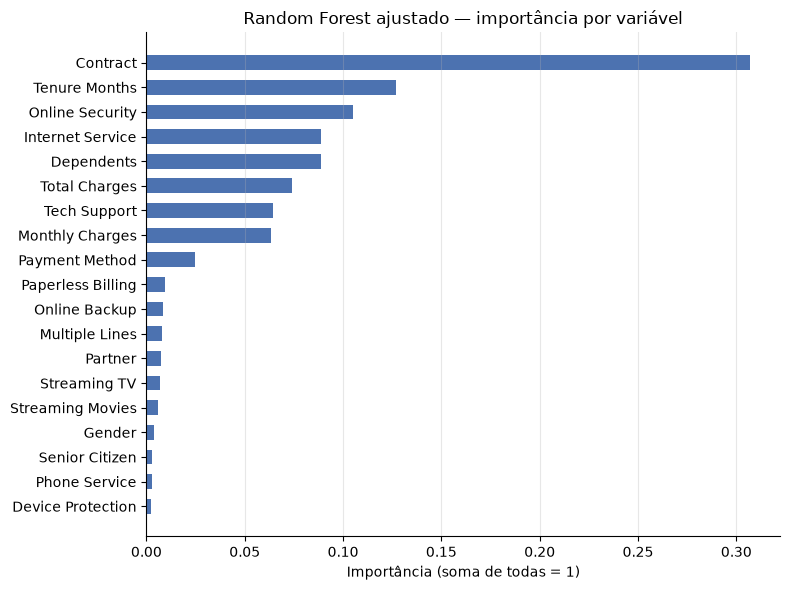

variavel
Contract             0.307
Tenure Months        0.127
Online Security      0.105
Internet Service     0.089
Dependents           0.089
Total Charges        0.074
Tech Support         0.064
Monthly Charges      0.063
Payment Method       0.025
Paperless Billing    0.009
Online Backup        0.008
Multiple Lines       0.008
Partner              0.007
Streaming TV         0.007
Streaming Movies     0.006
Gender               0.004
Senior Citizen       0.003
Phone Service        0.003
Device Protection    0.002
Name: importancia, dtype: float64

In [12]:
# Random Forest ajustado — importância das variáveis
import matplotlib.pyplot as plt

melhor_rf = busca_rf.best_estimator_
nomes = melhor_rf.named_steps["preprocessor"].get_feature_names_out()
importancias = melhor_rf.named_steps["classifier"].feature_importances_

# Junta as colunas criadas pelo OneHotEncoder na variável original
# (ex.: "cat__Contract_Month-to-month" → "Contract")
def variavel_original(nome):
    nome = nome.split("__", 1)[1]
    for col in numeric_cols + categorical_cols:
        if nome == col or nome.startswith(col + "_"):
            return col
    return nome

importancia_rf = (
    pd.DataFrame({"variavel": [variavel_original(n) for n in nomes], "importancia": importancias})
    .groupby("variavel")["importancia"].sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importancia_rf.index, importancia_rf.values, color="#4C72B0", height=0.6)
ax.set_xlabel("Importância (soma de todas = 1)")
ax.set_title("Random Forest ajustado — importância por variável")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

importancia_rf.sort_values(ascending=False).round(3)

## 4. Rede Neural (MLP)

O `MLPClassifier` tem camadas ocultas de neurônios entre a entrada e a saída. Cada neurônio
combina todas as variáveis ao mesmo tempo e aprende a reconhecer um padrão de cliente; a camada
de saída combina esses padrões na probabilidade de churn.

- Usa o mesmo `preprocessor_escalado` da Regressão Logística: redes neurais são sensíveis à
  escala das variáveis.
- `early_stopping=True`: separa 10% do treino de cada rodada como controle e interrompe o
  treinamento quando o desempenho nesse controle para de melhorar (proteção contra overfitting).

In [13]:
# MLP — primeira rodada: 1 camada oculta com 32 neurônios (referência)
from sklearn.neural_network import MLPClassifier

modelo_mlp = Pipeline([
    ("preprocessor", preprocessor_escalado),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32,),
        early_stopping=True,
        max_iter=500,
        random_state=SEED,
    )),
])

resultado_mlp = cross_validate(
    modelo_mlp, X_train, y_train,
    cv=cv, scoring=METRICAS,
)

registrar_experimento("MLP (padrão)", resultado_mlp,
                      "hidden_layer_sizes=(32,), early_stopping")
salvar_experimentos()
tabela_experimentos()

,AUC-ROC,Recall,Precision,F1,Tempo treino (s),Hiperparâmetros
Modelo,,,,,,
Regressão Logística (baseline),0.859 ± 0.013,0.582 ± 0.042,0.667 ± 0.024,0.621 ± 0.029,0.03,"padrão (C=1, L2), sem class_weight"
Regressão Logística (ajustada),0.859 ± 0.013,0.585 ± 0.043,0.665 ± 0.025,0.621 ± 0.031,0.03,"GridSearchCV: C=100, l1_ratio=0"
Random Forest (padrão),0.837 ± 0.013,0.513 ± 0.029,0.652 ± 0.027,0.574 ± 0.028,0.14,"padrão do sklearn (100 árvores, sem limite de ..."
Random Forest (ajustado),0.864 ± 0.010,0.551 ± 0.022,0.673 ± 0.031,0.605 ± 0.020,0.43,RandomizedSearchCV (30 combinações): n_estimat...
MLP (padrão),0.850 ± 0.011,0.497 ± 0.063,0.680 ± 0.034,0.571 ± 0.045,0.14,"hidden_layer_sizes=(32,), early_stopping"


### Ajuste de hiperparâmetros da MLP

- `hidden_layer_sizes`: quantas camadas ocultas e quantos neurônios em cada uma
  (ex.: `(64, 32)` = duas camadas, com 64 e 32 neurônios).
- `alpha`: força da regularização (mesma ideia do `C` da Regressão Logística, mas no sentido
  direto: `alpha` maior = mais "freio").
- `learning_rate_init`: tamanho do passo de aprendizado a cada iteração.

Busca aleatória com 20 combinações, mesma validação cruzada e seleção por AUC-ROC.

In [14]:
# MLP — ajuste de hiperparâmetros (busca aleatória, seleção por AUC-ROC)
grade_mlp = {
    "classifier__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
    "classifier__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0],
    "classifier__learning_rate_init": [0.001, 0.01],
}

busca_mlp = RandomizedSearchCV(
    modelo_mlp, grade_mlp,
    n_iter=20, cv=cv, scoring="roc_auc",
    random_state=SEED, n_jobs=-1,
)
busca_mlp.fit(X_train, y_train)

print("Melhor combinação:", formatar_params(busca_mlp.best_params_))
print(f"Melhor AUC (CV): {busca_mlp.best_score_:.3f}")

# Reavalia a melhor combinação com as 4 métricas, no mesmo esquema de CV, para registrar
resultado_mlp_ajustado = cross_validate(
    busca_mlp.best_estimator_, X_train, y_train,
    cv=cv, scoring=METRICAS,
)
registrar_experimento("MLP (ajustada)", resultado_mlp_ajustado,
                      "RandomizedSearchCV (20 combinações): " + formatar_params(busca_mlp.best_params_))
salvar_experimentos()
tabela_experimentos()

Melhor combinação: learning_rate_init=0.01, hidden_layer_sizes=(32,), alpha=0.001
Melhor AUC (CV): 0.859


,AUC-ROC,Recall,Precision,F1,Tempo treino (s),Hiperparâmetros
Modelo,,,,,,
Regressão Logística (baseline),0.859 ± 0.013,0.582 ± 0.042,0.667 ± 0.024,0.621 ± 0.029,0.03,"padrão (C=1, L2), sem class_weight"
Regressão Logística (ajustada),0.859 ± 0.013,0.585 ± 0.043,0.665 ± 0.025,0.621 ± 0.031,0.03,"GridSearchCV: C=100, l1_ratio=0"
Random Forest (padrão),0.837 ± 0.013,0.513 ± 0.029,0.652 ± 0.027,0.574 ± 0.028,0.14,"padrão do sklearn (100 árvores, sem limite de ..."
Random Forest (ajustado),0.864 ± 0.010,0.551 ± 0.022,0.673 ± 0.031,0.605 ± 0.020,0.43,RandomizedSearchCV (30 combinações): n_estimat...
MLP (padrão),0.850 ± 0.011,0.497 ± 0.063,0.680 ± 0.034,0.571 ± 0.045,0.14,"hidden_layer_sizes=(32,), early_stopping"
MLP (ajustada),0.859 ± 0.013,0.580 ± 0.036,0.669 ± 0.032,0.620 ± 0.025,0.13,RandomizedSearchCV (20 combinações): learning_...


## 5. Comparação dos modelos

Tabela completa em `docs/experimentos.md`. A curva ROC abaixo usa as mesmas 5 rodadas de
validação cruzada (apenas treino — o teste continua reservado).

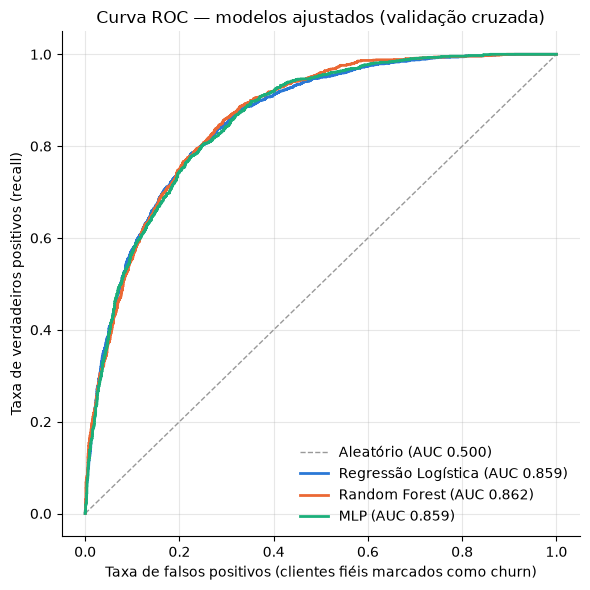

In [15]:
# Curvas ROC dos 3 modelos ajustados, com probabilidades fora da amostra (cross_val_predict)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

# Cores fixas por família de modelo
CORES = {"Regressão Logística": "#2a78d6", "Random Forest": "#eb6834", "MLP": "#1baf7a"}

modelos_ajustados = {
    "Regressão Logística": busca_logreg.best_estimator_,
    "Random Forest": busca_rf.best_estimator_,
    "MLP": busca_mlp.best_estimator_,
}

# Probabilidade de churn de cada cliente do treino, prevista pelo modelo que NÃO o viu no treino
# (guardadas para reutilizar no Passo 6: calibração e segmentação)
proba_cv = {
    nome: cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for nome, modelo in modelos_ajustados.items()
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="#999", linewidth=1, label="Aleatório (AUC 0.500)")
for nome, proba in proba_cv.items():
    fpr, tpr, _ = roc_curve(y_train, proba)
    ax.plot(fpr, tpr, color=CORES[nome], linewidth=2,
            label=f"{nome} (AUC {roc_auc_score(y_train, proba):.3f})")

ax.set_xlabel("Taxa de falsos positivos (clientes fiéis marcados como churn)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC — modelos ajustados (validação cruzada)")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Calibração das probabilidades e faixas de risco — Regressão Logística

**Modelo escolhido: Regressão Logística.** Os três modelos ajustados ordenam os clientes de forma
equivalente (AUC-ROC ~0,86, diferenças menores que a variação entre rodadas), e a Regressão
Logística entrega esse desempenho com o menor tempo de processamento e maior simplicidade.
Por isso a calibração e as faixas de risco são analisadas apenas para ela.

O uso de negócio previsto é **segmentar os clientes pela probabilidade de churn** (retenção
agressiva / retenção conservadora / apenas acompanhamento). Para isso, a probabilidade precisa
ser **confiável**: entre os clientes com probabilidade prevista de ~70%, cerca de 70% devem
realmente cancelar. Isso é a **calibração**.

- **Curva de calibração:** compara a probabilidade prevista (eixo X) com a taxa real de churn
  (eixo Y). Um modelo perfeitamente calibrado fica sobre a diagonal.
- **Brier score:** erro médio entre a probabilidade prevista e o resultado real (0 ou 1).
  Quanto menor, melhor.

Usa as probabilidades de validação cruzada (`proba_cv`) do treino — o teste continua reservado.

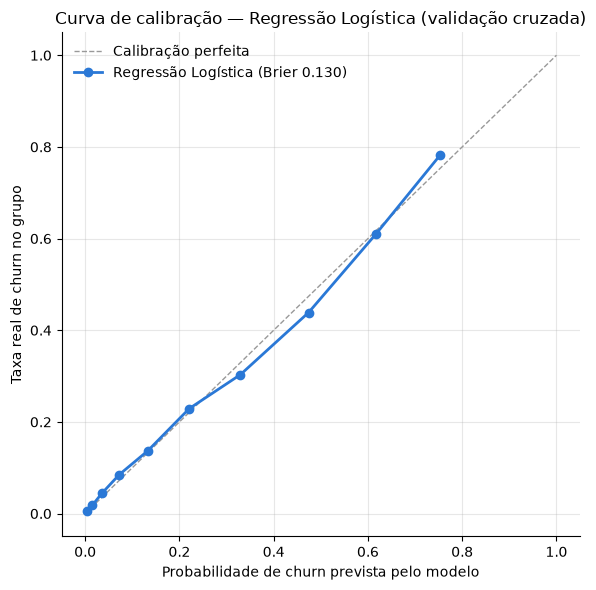

In [16]:
# Curva de calibração da Regressão Logística (modelo escolhido) + Brier score
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

MODELO_ESCOLHIDO = "Regressão Logística"
proba_escolhido = proba_cv[MODELO_ESCOLHIDO]

taxa_real, proba_media = calibration_curve(y_train, proba_escolhido, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_train, proba_escolhido)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="#999", linewidth=1, label="Calibração perfeita")
ax.plot(proba_media, taxa_real, marker="o", markersize=6, linewidth=2,
        color=CORES[MODELO_ESCOLHIDO], label=f"{MODELO_ESCOLHIDO} (Brier {brier:.3f})")

ax.set_xlabel("Probabilidade de churn prevista pelo modelo")
ax.set_ylabel("Taxa real de churn no grupo")
ax.set_title("Curva de calibração — Regressão Logística (validação cruzada)")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Faixas de probabilidade

Para cada faixa de probabilidade prevista: quantos clientes caem nela, qual a taxa real de churn
e qual o **recall acumulado** — a porcentagem de todos os churners reais que seriam alcançados se
o corte fosse colocado no início daquela faixa (todos os clientes daquela faixa para cima).
Base para a escolha dos 2 cortes de segmentação.

In [17]:
# Tabela por faixas de probabilidade (10 em 10 pontos percentuais)
FAIXAS = np.round(np.arange(0, 1.01, 0.1), 1)

def tabela_faixas(proba, y_real):
    dados = pd.DataFrame({
        "faixa": pd.cut(proba, bins=FAIXAS, include_lowest=True, right=False),
        "proba": proba,
        "churn": y_real.to_numpy(),
    })
    tabela = dados.groupby("faixa", observed=False).agg(
        clientes=("churn", "size"),
        churners=("churn", "sum"),
        proba_media=("proba", "mean"),
        taxa_real=("churn", "mean"),
    )
    total_churners = tabela["churners"].sum()
    # recall acumulado de cima para baixo: churners alcançados se o corte for o início da faixa
    tabela["recall_acumulado"] = tabela["churners"][::-1].cumsum()[::-1] / total_churners
    tabela["pct_clientes_acumulado"] = tabela["clientes"][::-1].cumsum()[::-1] / tabela["clientes"].sum()
    return tabela.round(3)

tabela_faixas(proba_escolhido, y_train)


,clientes,churners,proba_media,taxa_real,recall_acumulado,pct_clientes_acumulado
faixa,,,,,,
"[0.0, 0.1)",2284,89,0.033,0.039,1.000,1.000
"[0.1, 0.2)",678,93,0.146,0.137,0.940,0.595
"[0.2, 0.3)",574,143,0.247,0.249,0.878,0.474
"[0.3, 0.4)",419,143,0.348,0.341,0.783,0.372
"[0.4, 0.5)",364,153,0.449,0.420,0.687,0.298
"[0.5, 0.6)",392,210,0.552,0.536,0.585,0.233
"[0.6, 0.7)",420,264,0.649,0.629,0.444,0.164
"[0.7, 0.8)",402,312,0.744,0.776,0.268,0.089
"[0.8, 0.9)",101,88,0.824,0.871,0.059,0.018


### Notas do autor

- **Modelo vencedor: Regressão Logística.** Oferece o melhor equilíbrio entre indicadores e tempo
  de processamento: AUC-ROC equivalente ao Random Forest e à MLP, com treinamento cerca de 10x mais
  rápido que o Random Forest.
- **Preocupação com o recall:** existe uma faixa ampla de clientes intermediários nos quais será
  necessário fazer gestão de retenção sem ter clareza de que realmente vão cancelar o serviço.

### Segmentação de risco (decisão do autor)

| Segmento | Probabilidade de churn | Ação de negócio |
|---|---|---|
| **Acompanhamento** | < 20% | Nenhuma ação específica. |
| **Retenção conservadora** | 20% a < 50% | Gestão comercial para induzir a contratação de produtos que funcionam como barreira de saída: mudança do tipo de contrato, do tipo de serviço, inclusão de dependentes. |
| **Retenção agressiva** | ≥ 50% | Os mesmos produtos de barreira de saída, com bonificação de 1 mês de serviço grátis. |

As ações se apoiam nas variáveis mais relevantes encontradas pelos modelos (`Contract`,
`Dependents`, `Online Security`, `Tech Support`, `Internet Service`).

In [18]:
# Cortes de segmentação definidos pelo autor
CORTES = [0.20, 0.50]
SEGMENTOS = ["Acompanhamento", "Retenção conservadora", "Retenção agressiva"]

def segmentar(proba):
    return pd.cut(proba, bins=[0, *CORTES, 1], labels=SEGMENTOS, include_lowest=True, right=False)

resumo = (
    pd.DataFrame({"segmento": segmentar(proba_escolhido), "churn": y_train.to_numpy()})
    .groupby("segmento", observed=False)
    .agg(clientes=("churn", "size"), churners=("churn", "sum"), taxa_real=("churn", "mean"))
)
resumo["pct_clientes"] = resumo["clientes"] / resumo["clientes"].sum()
resumo["pct_dos_churners"] = resumo["churners"] / resumo["churners"].sum()

recall_acionado = resumo.loc[SEGMENTOS[1:], "churners"].sum() / resumo["churners"].sum()
print(f"Recall dos segmentos com ação (conservadora + agressiva): {recall_acionado:.1%}")
resumo.round(3)

Recall dos segmentos com ação (conservadora + agressiva): 87.8%


,clientes,churners,taxa_real,pct_clientes,pct_dos_churners
segmento,,,,,
Acompanhamento,2962,182,0.061,0.526,0.122
Retenção conservadora,1357,439,0.324,0.241,0.294
Retenção agressiva,1315,874,0.665,0.233,0.585


## 7. Auditoria de vieses (Fairlearn)

Compromisso do ML Canvas (seção 7): verificar se o modelo **distribui o benefício de retenção de
forma desigual** entre grupos sensíveis. O risco não é punitivo — o modelo concede benefícios —,
mas um grupo cujo risco seja sistematicamente subestimado receberia menos ações de retenção que
outro grupo com o mesmo risco real.

Grupos auditados: `Gender` e `Senior Citizen`. As variáveis de localização (`City`, `State`,
`Zip Code`) não entram no modelo.

Para cada grupo, com as probabilidades de validação cruzada da Regressão Logística:
- **churn real × probabilidade média prevista:** se a diferença for grande, o modelo sub ou
  superestima o risco daquele grupo (calibração por grupo);
- **% com ação:** clientes nos segmentos conservador ou agressivo (probabilidade ≥ 20%);
- **recall com ação:** dos churners reais do grupo, quantos receberiam alguma ação;
- **% agressiva:** clientes que receberiam o benefício de 1 mês grátis (probabilidade ≥ 50%).

In [19]:
# Auditoria de vieses por grupo sensível (Fairlearn MetricFrame)
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, equalized_odds_difference

com_acao = (proba_escolhido >= CORTES[0]).astype(int)      # conservadora ou agressiva
agressiva = (proba_escolhido >= CORTES[1]).astype(int)

def auditar(grupo):
    sensivel = X_train[grupo].to_numpy()
    mf = MetricFrame(
        metrics={
            "churn_real": lambda y, p: y.mean(),
            "% com ação": selection_rate,
            "recall com ação": true_positive_rate,
        },
        y_true=y_train, y_pred=com_acao, sensitive_features=sensivel,
    )
    tabela = mf.by_group.rename_axis(grupo)
    tabela.insert(1, "proba_media", pd.Series(proba_escolhido).groupby(sensivel).mean())
    tabela.insert(0, "clientes", pd.Series(sensivel).value_counts())
    tabela["% agressiva"] = pd.Series(agressiva).groupby(sensivel).mean()
    eo = equalized_odds_difference(y_train, com_acao, sensitive_features=sensivel)
    print(f"=== {grupo} — diferença de equalized odds: {eo:.3f} ===")
    display(tabela.round(3))

for grupo in ["Gender", "Senior Citizen"]:
    auditar(grupo)

=== Gender — diferença de equalized odds: 0.018 ===


,clientes,churn_real,proba_media,% com ação,recall com ação,% agressiva
Gender,,,,,,
Female,2801,0.266,0.267,0.473,0.887,0.240
Male,2833,0.264,0.264,0.475,0.869,0.227


=== Senior Citizen — diferença de equalized odds: 0.257 ===


,clientes,churn_real,proba_media,% com ação,recall com ação,% agressiva
Senior Citizen,,,,,,
No,4714,0.237,0.237,0.428,0.857,0.195
Yes,920,0.411,0.412,0.712,0.942,0.433


In [20]:
# Recall por grupo: corte único de 50% (uso binário) × segmentação proposta (ação a partir de 20%)
churners = y_train.to_numpy() == 1
comparacao = pd.DataFrame({
    "recall corte 50%": pd.Series(agressiva[churners]).groupby(X_train["Senior Citizen"].to_numpy()[churners]).mean(),
    "recall segmentação": pd.Series(com_acao[churners]).groupby(X_train["Senior Citizen"].to_numpy()[churners]).mean(),
}).rename_axis("Senior Citizen")
comparacao["ganho (p.p.)"] = (comparacao["recall segmentação"] - comparacao["recall corte 50%"]) * 100
comparacao.round(3)

,recall corte 50%,recall segmentação,ganho (p.p.)
Senior Citizen,,,
No,0.541,0.857,31.603
Yes,0.714,0.942,22.751


### Notas do autor — vieses

- `Gender` e `Senior Citizen` têm baixa importância no modelo (fora das variáveis mais relevantes),
  por isso não serão aprofundadas além desta auditoria.
- **Gênero:** sem diferenças entre grupos (diferença de equalized odds 0,018).
- **Idosos:** recebem mais ações de retenção (71% contra 43%) porque seu churn real é maior (41%
  contra 24%); o modelo não sub nem superestima o risco de nenhum dos grupos (probabilidade média
  igual à taxa real). Do ponto de vista de justiça, a diferença de cobertura não preocupa: favorece
  um grupo vulnerável e pode ser registrada em auditoria como uma **decisão de caráter social**.
- **Recall:** a segmentação melhora a cobertura nos dois grupos em relação ao corte único de 50% —
  idosos de 71% para 94% e não idosos de 54% para 86%, o maior ganho.

## 8. Avaliação final no conjunto de teste

Primeira e única utilização dos 1.409 clientes reservados no início (20%). O modelo campeão
(Regressão Logística ajustada) já foi re-treinado pelo `GridSearchCV` com **todo** o conjunto de
treino; aqui ele apenas prevê clientes que nunca viu. Objetivo: confirmar se AUC, calibração e
recall da segmentação obtidos na validação cruzada se sustentam.

In [21]:
# Avaliação final do campeão no teste (uso único)
from sklearn.metrics import recall_score, precision_score, f1_score

campeao = busca_logreg.best_estimator_   # re-treinado com todo o X_train (refit do GridSearchCV)
proba_teste = campeao.predict_proba(X_test)[:, 1]

pred_corte50 = (proba_teste >= 0.5).astype(int)
acao_teste = (proba_teste >= CORTES[0]).astype(int)

comparacao_final = pd.DataFrame({
    "Baseline Etapa 1 (teste)": {
        "AUC-ROC": 0.849, "Brier": np.nan, "Recall corte 50%": 0.57, "Recall segmentação": np.nan,
    },
    "Campeão — validação cruzada (treino)": {
        "AUC-ROC": roc_auc_score(y_train, proba_escolhido),
        "Brier": brier_score_loss(y_train, proba_escolhido),
        "Recall corte 50%": recall_score(y_train, (proba_escolhido >= 0.5).astype(int)),
        "Recall segmentação": recall_score(y_train, (proba_escolhido >= CORTES[0]).astype(int)),
    },
    "Campeão — teste": {
        "AUC-ROC": roc_auc_score(y_test, proba_teste),
        "Brier": brier_score_loss(y_test, proba_teste),
        "Recall corte 50%": recall_score(y_test, pred_corte50),
        "Recall segmentação": recall_score(y_test, acao_teste),
    },
}).round(3)
comparacao_final

,Baseline Etapa 1 (teste),Campeão — validação cruzada (treino),Campeão — teste
AUC-ROC,0.849,0.859,0.848
Brier,NaN,0.130,0.136
Recall corte 50%,0.570,0.585,0.567
Recall segmentação,NaN,0.878,0.856


In [22]:
# Segmentação aplicada ao teste: a taxa real de churn por segmento se mantém?
resumo_teste = (
    pd.DataFrame({"segmento": segmentar(proba_teste), "proba": proba_teste, "churn": y_test.to_numpy()})
    .groupby("segmento", observed=False)
    .agg(clientes=("churn", "size"), churners=("churn", "sum"),
         proba_media=("proba", "mean"), taxa_real=("churn", "mean"))
)
resumo_teste["pct_clientes"] = resumo_teste["clientes"] / resumo_teste["clientes"].sum()
resumo_teste["pct_dos_churners"] = resumo_teste["churners"] / resumo_teste["churners"].sum()
resumo_teste.round(3)

,clientes,churners,proba_media,taxa_real,pct_clientes,pct_dos_churners
segmento,,,,,,
Acompanhamento,737,54,0.058,0.073,0.523,0.144
Retenção conservadora,332,108,0.333,0.325,0.236,0.289
Retenção agressiva,340,212,0.657,0.624,0.241,0.567


## 9. Salvamento do modelo campeão

- `models/champion_model.joblib`: o `Pipeline` completo (pré-processamento + Regressão Logística).
  Recebe os dados brutos do cliente e devolve a probabilidade de churn.
- `models/champion_metadata.json`: cortes de segmentação, nomes dos segmentos, ações de negócio,
  features esperadas, hiperparâmetros e métricas. A API da Etapa 3 lê este arquivo para responder
  **probabilidade + segmento + ação**.

In [23]:
# Salva o pipeline campeão e os metadados de segmentação
import json
from datetime import date
import joblib
import sklearn

joblib.dump(campeao, "../models/champion_model.joblib")

metadata = {
    "modelo": "Regressão Logística ajustada",
    "data_treinamento": date.today().isoformat(),
    "versao_sklearn": sklearn.__version__,
    "seed": SEED,
    "hiperparametros": {k.replace("classifier__", ""): v for k, v in busca_logreg.best_params_.items()},
    "features": {"numericas": numeric_cols, "categoricas": categorical_cols},
    "segmentacao": {
        "cortes": CORTES,
        "segmentos": [
            {"nome": SEGMENTOS[0], "faixa": f"< {CORTES[0]:.0%}",
             "acao": "Nenhuma ação específica"},
            {"nome": SEGMENTOS[1], "faixa": f"{CORTES[0]:.0%} a < {CORTES[1]:.0%}",
             "acao": "Gestão comercial: produtos de barreira de saída (contrato, tipo de serviço, dependentes)"},
            {"nome": SEGMENTOS[2], "faixa": f">= {CORTES[1]:.0%}",
             "acao": "Produtos de barreira de saída + 1 mês de serviço grátis"},
        ],
    },
    "metricas": {
        "validacao_cruzada": comparacao_final["Campeão — validação cruzada (treino)"].to_dict(),
        "teste": comparacao_final["Campeão — teste"].to_dict(),
    },
}
with open("../models/champion_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Modelo e metadados salvos em ../models/")

Modelo e metadados salvos em ../models/


In [24]:
# Conferência: o modelo recarregado reproduz exatamente as probabilidades do teste
modelo_recarregado = joblib.load("../models/champion_model.joblib")
proba_recarregado = modelo_recarregado.predict_proba(X_test)[:, 1]

assert np.allclose(proba_recarregado, proba_teste)
print(f"OK — AUC-ROC no teste com o modelo recarregado: {roc_auc_score(y_test, proba_recarregado):.3f}")

OK — AUC-ROC no teste com o modelo recarregado: 0.848

## 10. Conclusões da Etapa 2

**Modelo vencedor: Regressão Logística ajustada** (`C=100`, regularização L2).

**1. Entendimento dos dados.** Realizamos um entendimento detalhado dos dados disponíveis (7.043
clientes, taxa de churn de 26,5%), da sua estrutura e da qualidade das variáveis, e analisamos as
variáveis com maior relação com o cancelamento. As mais relevantes, de forma consistente entre a
Regressão Logística e o Random Forest, foram: **tipo de contrato** (`Contract`, a mais importante,
com ~31% da importância no Random Forest), **tempo como cliente** (`Tenure Months`), **segurança
online** (`Online Security`), **tipo de serviço de internet** (`Internet Service`),
**dependentes** (`Dependents`) e **suporte técnico** (`Tech Support`).

**2. Comparação de modelos.** Comparamos três famílias de modelos (Regressão Logística, Random
Forest e Rede Neural MLP), aplicando um pipeline metodológico: tratamento das variáveis dentro de
um `Pipeline` (sem vazamento de dados), validação cruzada estratificada de 5 rodadas e ajuste de
hiperparâmetros selecionando pelo AUC-ROC. Os três modelos ajustados ficaram tecnicamente
empatados (AUC-ROC entre 0,859 e 0,864, diferença menor que a variação entre rodadas). Escolhemos
a **Regressão Logística** pelo melhor equilíbrio entre desempenho, tempo de processamento (~10x
mais rápida que o Random Forest) e simplicidade de interpretação. Indicadores do modelo escolhido
(validação cruzada):

| Indicador | Valor |
|---|---|
| AUC-ROC | 0,859 ± 0,013 |
| Brier score (calibração) | 0,130 — probabilidades confiáveis, sem necessidade de correção |
| Recall com a segmentação proposta | **87,8%** (objetivo: 70–80%) |

**3. Proposta de uso do modelo.** Desenhamos uma proposta de uso que aproveita a qualidade
disponível do modelo, mitigando ao mesmo tempo o risco de investir em clientes que não vão sair e
o risco de não agir sobre clientes que poderiam sair:

| Segmento | Clientes | % da base | Churn real | % dos churners |
|---|---|---|---|---|
| Retenção agressiva (≥ 50%) | 1.315 | 23% | 66,5% | 58,5% |
| Retenção conservadora (20–50%) | 1.357 | 24% | 32,4% | 29,4% |
| Acompanhamento (< 20%) | 2.962 | 53% | 6,1% | 12,2% |

- **Menos investimento desperdiçado:** o benefício mais caro (1 mês grátis) vai apenas para 23% da
  base, onde 2 de cada 3 clientes realmente cancelariam.
- **Menos clientes sem ação:** as duas faixas com ação alcançam 87,8% dos churners reais, contra
  57% do baseline da Etapa 1 com corte único de 50%.
- **Foco onde não há ação:** 53% da base fica sem ação específica, e nela o churn real é de
  apenas 6,1%.

**Principal aprendizado:** o AUC praticamente não mudou entre o baseline e os modelos mais
complexos (~0,86). O ganho de recall (de 0,57 para 0,88) veio de **como o modelo é usado** —
trocar um corte único por uma segmentação por faixas de risco alinhada ao negócio —, e não de um
algoritmo mais sofisticado.